In [58]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [102]:
import pandas as pd

# Reload original dataset
df = pd.read_csv("data.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Check original diagnosis values
print("Original Diagnosis Values:")
print(df['diagnosis'].value_counts(dropna=False))

print("\nUnique Values:")
print(df['diagnosis'].unique())

print("\nDataset Shape:")
print(df.shape)

Original Diagnosis Values:
diagnosis
B    357
M    212
Name: count, dtype: int64

Unique Values:
['M' 'B']

Dataset Shape:
(569, 33)


In [103]:
# Remove unnecessary columns
df.drop(
    columns=['id', 'Unnamed: 32'],
    errors='ignore',
    inplace=True
)

# Convert diagnosis into numerical values
df['diagnosis'] = df['diagnosis'].map({
    'B': 0,
    'M': 1
})

print(df['diagnosis'].value_counts())
print("Missing values:", df['diagnosis'].isnull().sum())

diagnosis
0    357
1    212
Name: count, dtype: int64
Missing values: 0


In [104]:
X = df.drop('diagnosis', axis=1)

y = df['diagnosis']

print("Input Features:", X.shape)
print("Target Variable:", y.shape)

print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Input Features: (569, 30)
Target Variable: (569,)
Missing values in X: 0
Missing values in y: 0


In [106]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [108]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Target: (455,)
Testing Target: (114,)


In [110]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [112]:
print("Training Scaled Shape:", X_train_scaled.shape)
print("Testing Scaled Shape:", X_test_scaled.shape)

Training Scaled Shape: (455, 30)
Testing Scaled Shape: (114, 30)


In [114]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train_scaled, y_train)

print("KNN Model trained successfully!")

KNN Model trained successfully!


In [116]:
# Predict using test data
y_pred = knn.predict(X_test_scaled)

print("Predictions:")
print(y_pred[:10])

Predictions:
[0 1 0 0 0 0 1 0 0 0]


In [118]:
import pandas as pd

comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(comparison.head(10))

   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          0
4       0          0
5       0          0
6       1          1
7       0          0
8       0          0
9       0          0


In [120]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("KNN Model Accuracy:", accuracy * 100, "%")

KNN Model Accuracy: 95.6140350877193 %


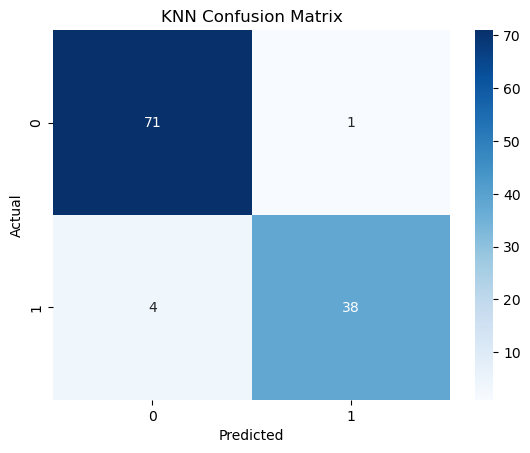

In [122]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

In [124]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.99      0.97        72
           1       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [126]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

metrics = ['minkowski', 'manhattan', 'hamming', 'chebyshev']

for metric in metrics:
    model = KNeighborsClassifier(n_neighbors=5, metric=metric)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, predictions)

    print(metric, "Accuracy:", accuracy * 100)

minkowski Accuracy: 95.6140350877193
manhattan Accuracy: 95.6140350877193
hamming Accuracy: 71.9298245614035
chebyshev Accuracy: 91.22807017543859


In [128]:
new_data = X_test.iloc[[0]]

new_data_scaled = scaler.transform(new_data)

prediction = knn.predict(new_data_scaled)

if prediction[0] == 0:
    print("Prediction: Benign")
else:
    print("Prediction: Malignant")

Prediction: Benign


In [130]:
import pandas as pd

comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(comparison.head(10))

   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          0
4       0          0
5       0          0
6       1          1
7       0          0
8       0          0
9       0          0


In [132]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("KNN Model Accuracy:", accuracy * 100, "%")

KNN Model Accuracy: 95.6140350877193 %


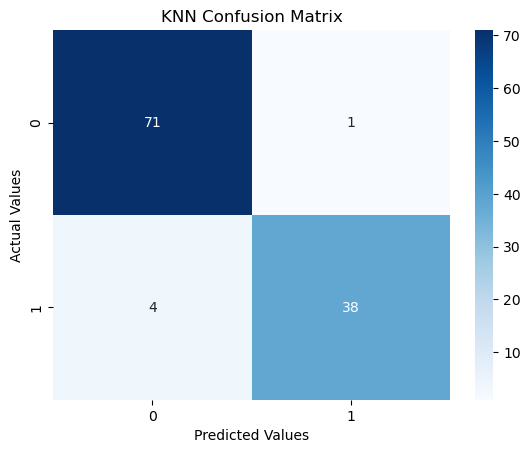

In [134]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("KNN Confusion Matrix")
plt.show()

In [136]:
from sklearn.metrics import classification_report

print("KNN Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Benign', 'Malignant']
))

KNN Classification Report:

              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [138]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

metrics = ['minkowski', 'manhattan', 'hamming', 'chebyshev']

results = []

for metric in metrics:

    model = KNeighborsClassifier(
        n_neighbors=5,
        metric=metric
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        'Distance Metric': metric,
        'Accuracy': accuracy * 100
    })

results_df = pd.DataFrame(results)

print(results_df)

  Distance Metric   Accuracy
0       minkowski  95.614035
1       manhattan  95.614035
2         hamming  71.929825
3       chebyshev  91.228070


In [140]:
# Select one unseen sample from test data
new_data = X_test.iloc[[0]]

# Apply feature scaling
new_data_scaled = scaler.transform(new_data)

# Predict using KNN model
prediction = knn.predict(new_data_scaled)

# Display result
if prediction[0] == 0:
    print("Prediction: Benign")
else:
    print("Prediction: Malignant")

Prediction: Benign


In [142]:
print("BREAST CANCER CLASSIFICATION USING KNN")
print("--------------------------------------")

print("Dataset Shape:", df.shape)
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("Number of Features:", X.shape[1])
print("KNN Neighbors:", knn.n_neighbors)

print("Final Model Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

print("\nProject Completed Successfully!")

BREAST CANCER CLASSIFICATION USING KNN
--------------------------------------
Dataset Shape: (569, 31)
Training Samples: 455
Testing Samples: 114
Number of Features: 30
KNN Neighbors: 5
Final Model Accuracy: 95.6140350877193 %

Project Completed Successfully!
